In [1]:
# IMPORTANT: RUN THIS CELL IN ORDER TO IMPORT YOUR KAGGLE DATA SOURCES,
# THEN FEEL FREE TO DELETE THIS CELL.
# NOTE: THIS NOTEBOOK ENVIRONMENT DIFFERS FROM KAGGLE'S PYTHON
# ENVIRONMENT SO THERE MAY BE MISSING LIBRARIES USED BY YOUR
# NOTEBOOK.
import kagglehub
haseebindata_student_performance_predictions_path = kagglehub.dataset_download('haseebindata/student-performance-predictions')

print('Data source import complete.')


100%|██████████| 20.6k/20.6k [00:00<00:00, 26.7MB/s]

Extracting files...
Data source import complete.


In [ ]:
import pandas as pd
import numpy as np

In [2]:
import os

dataset_path = haseebindata_student_performance_predictions_path

for root, dirs, files in os.walk(dataset_path):
    for file in files:
        print(os.path.join(root, file))

/root/.cache/kagglehub/datasets/haseebindata/student-performance-predictions/versions/4/student_performance_updated_1000.csv


In [ ]:
df=pd.read_csv(r"/kaggle/input/student-performance-predictions/student_performance.csv")
df

In [ ]:
df.info()

****
### Data Visualization
****

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt

In [ ]:
tdf=df['Gender'].value_counts().reset_index()
tdf.columns=['Gender','count']
tdf1=df['ExtracurricularActivities'].value_counts().reset_index()
tdf1.columns=['ExtracurricularActivities','count']
tdf2=df['ParentalSupport'].value_counts().reset_index()
tdf2.columns=['ParentalSupport','count']
fig,axs=plt.subplots(1,3,figsize=(13,13))
axs[0].set_title("Distribution of Gender")
axs[0].pie(x=tdf['count'],labels=tdf['Gender'],autopct='%.2f%%')
axs[0].legend(tdf['Gender'])
axs[1].set_title("Distribution of Extra Curricular Activities")
axs[1].pie(x=tdf1['count'],labels=tdf1['ExtracurricularActivities'],autopct='%.2f%%')
axs[1].legend(tdf1['ExtracurricularActivities'])
axs[2].set_title("Distribution of Parental Support")
axs[2].pie(x=tdf2['count'],labels=tdf2['ParentalSupport'],autopct='%.2f%%')
axs[2].legend(tdf2['ParentalSupport'])
plt.tight_layout()
plt.show()

In [3]:
import pandas as pd

df = pd.read_csv(
    haseebindata_student_performance_predictions_path
    + "/student_performance_updated_1000.csv"
)

display(df.head())
print("Dataset shape:", df.shape)

,StudentID,Name,Gender,AttendanceRate,StudyHoursPerWeek,PreviousGrade,ExtracurricularActivities,ParentalSupport,FinalGrade,Study Hours,Attendance (%),Online Classes Taken
0,1.0,John,Male,85.0,15.0,78.0,1.0,High,80.0,4.8,59.0,False
1,2.0,Sarah,Female,90.0,20.0,85.0,2.0,Medium,87.0,2.2,70.0,True
2,3.0,Alex,Male,78.0,10.0,65.0,0.0,Low,68.0,4.6,92.0,False
3,4.0,Michael,Male,92.0,25.0,90.0,3.0,High,92.0,2.9,96.0,False
4,5.0,Emma,Female,NaN,18.0,82.0,2.0,Medium,85.0,4.1,97.0,True


Dataset shape: (1000, 12)


Dataset Information
--------------------
Total Rows: 1000
Total Columns: 12

Column Names:
['StudentID', 'Name', 'Gender', 'AttendanceRate', 'StudyHoursPerWeek', 'PreviousGrade', 'ExtracurricularActivities', 'ParentalSupport', 'FinalGrade', 'Study Hours', 'Attendance (%)', 'Online Classes Taken']

Missing Values:
StudentID                    40
Name                         34
Gender                       48
AttendanceRate               40
StudyHoursPerWeek            50
PreviousGrade                33
ExtracurricularActivities    43
ParentalSupport              22
FinalGrade                   40
Study Hours                  24
Attendance (%)               41
Online Classes Taken         25
dtype: int64

Statistical Summary:


,StudentID,AttendanceRate,StudyHoursPerWeek,PreviousGrade,ExtracurricularActivities,FinalGrade,Study Hours,Attendance (%)
count,960.000000,960.000000,950.000000,967.000000,957.000000,960.000000,976.000000,959.000000
mean,5416.019792,85.510417,17.630526,77.598759,1.520376,80.030208,2.406967,77.248175
std,2653.748319,7.332125,6.272132,10.006640,1.046439,9.493652,1.620267,19.298148
min,1.000000,70.000000,8.000000,60.000000,0.000000,62.000000,-5.000000,50.000000
25%,3113.500000,82.000000,12.000000,70.000000,1.000000,72.000000,1.200000,63.000000
50%,5396.500000,88.000000,18.000000,78.000000,1.000000,80.000000,2.500000,76.000000
75%,7754.750000,91.000000,22.000000,86.000000,2.000000,88.000000,3.700000,89.000000
max,9998.000000,95.000000,30.000000,90.000000,3.000000,92.000000,5.000000,200.000000


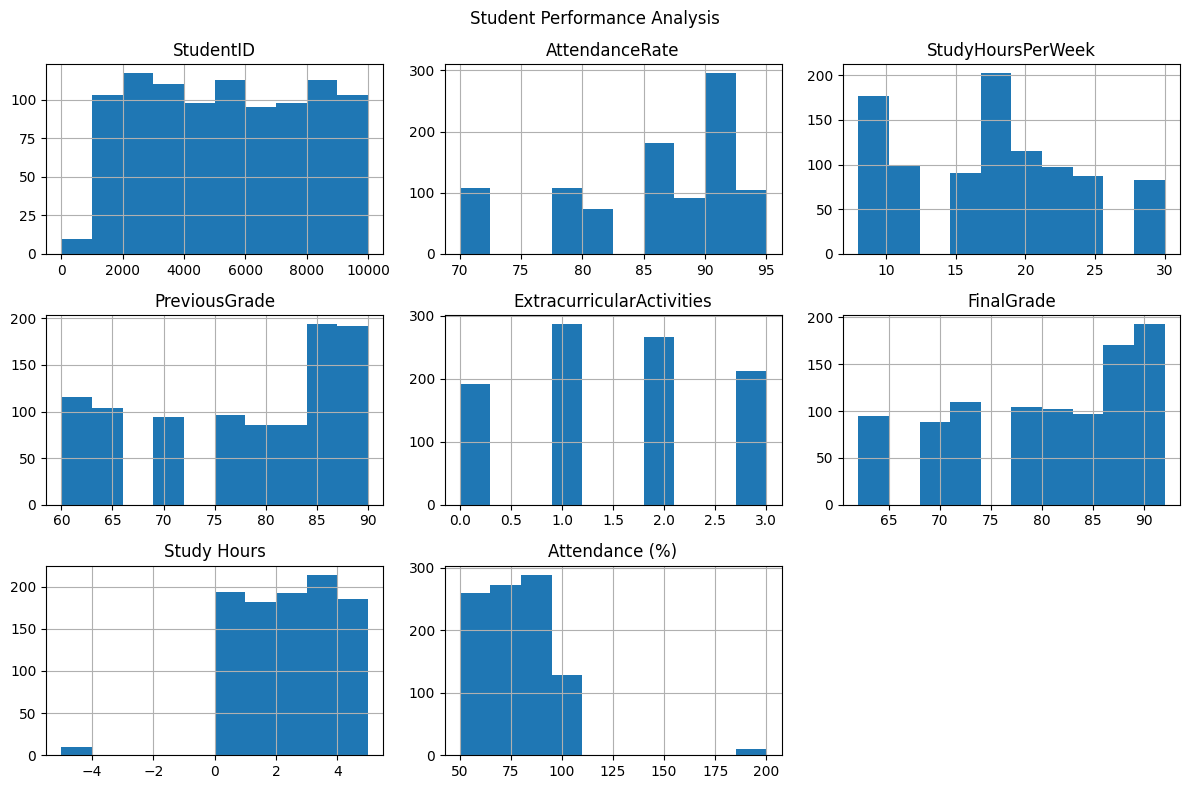

Dataset analysis completed successfully!


In [5]:
# Check dataset
print("Dataset Information")
print("--------------------")
print("Total Rows:", df.shape[0])
print("Total Columns:", df.shape[1])

print("\nColumn Names:")
print(df.columns.tolist())

print("\nMissing Values:")
print(df.isnull().sum())

print("\nStatistical Summary:")
display(df.describe())

# Visualize student performance
import matplotlib.pyplot as plt

df.hist(figsize=(12, 8))
plt.suptitle("Student Performance Analysis")
plt.tight_layout()
plt.show()

print("Dataset analysis completed successfully!")

In [6]:
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, r2_score
import pandas as pd

# Select numerical columns
data = df.select_dtypes(include='number').dropna()

# Select target column
target = 'final_score' if 'final_score' in data.columns else data.columns[-1]

X = data.drop(columns=[target])
y = data[target]

# Split dataset
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# Train model
model = RandomForestRegressor(n_estimators=100, random_state=42)
model.fit(X_train, y_train)

# Predict results
predictions = model.predict(X_test)

print("STUDENT PERFORMANCE PREDICTION")
print("--------------------------------")
print("Model trained successfully!")
print("Target column:", target)
print("Mean Absolute Error:", round(mean_absolute_error(y_test, predictions), 2))
print("R2 Score:", round(r2_score(y_test, predictions), 2))

results = pd.DataFrame({
    "Actual Marks": y_test.values[:10],
    "Predicted Marks": predictions[:10].round(2)
})

display(results)

STUDENT PERFORMANCE PREDICTION
--------------------------------
Model trained successfully!
Target column: Attendance (%)
Mean Absolute Error: 13.44
R2 Score: 0.23


,Actual Marks,Predicted Marks
0,73.0,74.98
1,84.0,70.79
2,88.0,76.08
3,64.0,69.75
4,85.0,77.39
5,95.0,78.99
6,57.0,81.32
7,53.0,72.82
8,55.0,70.80
9,94.0,72.04


In [7]:
# Predict student performance

sample_student = X.iloc[[0]]
predicted_marks = model.predict(sample_student)

print("STUDENT PERFORMANCE PREDICTION")
print("--------------------------------")
print("Student Details:")
display(sample_student)

print("Predicted", target, ":", round(predicted_marks[0], 2))
print("--------------------------------")
print("Prediction completed successfully!")

STUDENT PERFORMANCE PREDICTION
--------------------------------
Student Details:


,StudentID,AttendanceRate,StudyHoursPerWeek,PreviousGrade,ExtracurricularActivities,FinalGrade,Study Hours
0,1.0,85.0,15.0,78.0,1.0,80.0,4.8


Predicted Attendance (%) : 62.95
--------------------------------
Prediction completed successfully!


In [8]:
import pickle
import pandas as pd

with open("student_performance_model.pkl", "wb") as f:
    pickle.dump(model, f)

df.to_csv("student_performance_dataset.csv", index=False)

print("Model saved successfully!")
print("Dataset saved successfully!")

Model saved successfully!
Dataset saved successfully!


In [9]:
print("Dataset columns:")
print(df.columns.tolist())

print("\nModel features:")
print(X.columns.tolist())

print("\nPrediction target:")
print(target)

Dataset columns:
['StudentID', 'Name', 'Gender', 'AttendanceRate', 'StudyHoursPerWeek', 'PreviousGrade', 'ExtracurricularActivities', 'ParentalSupport', 'FinalGrade', 'Study Hours', 'Attendance (%)', 'Online Classes Taken']

Model features:
['StudentID', 'AttendanceRate', 'StudyHoursPerWeek', 'PreviousGrade', 'ExtracurricularActivities', 'FinalGrade', 'Study Hours']

Prediction target:
Attendance (%)


In [10]:
!pip -q install streamlit

import pandas as pd

print("Dataset loaded:", df.shape)
print("Prediction target:", target)
print("Model ready:", model is not None)
print("Dashboard setup started!")

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.4/10.4 MB 73.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.4/11.4 MB 88.2 MB/s eta 0:00:00
Dataset loaded: (1000, 12)
Prediction target: Attendance (%)
Model ready: True
Dashboard setup started!


     STUDENT PERFORMANCE DASHBOARD

1. DATASET OVERVIEW
Total Students: 1000
Total Columns: 12

2. DATASET PREVIEW


,StudentID,Name,Gender,AttendanceRate,StudyHoursPerWeek,PreviousGrade,ExtracurricularActivities,ParentalSupport,FinalGrade,Study Hours,Attendance (%),Online Classes Taken
0,1.0,John,Male,85.0,15.0,78.0,1.0,High,80.0,4.8,59.0,False
1,2.0,Sarah,Female,90.0,20.0,85.0,2.0,Medium,87.0,2.2,70.0,True
2,3.0,Alex,Male,78.0,10.0,65.0,0.0,Low,68.0,4.6,92.0,False
3,4.0,Michael,Male,92.0,25.0,90.0,3.0,High,92.0,2.9,96.0,False
4,5.0,Emma,Female,NaN,18.0,82.0,2.0,Medium,85.0,4.1,97.0,True
5,6.0,Olivia,Female,95.0,30.0,88.0,1.0,High,NaN,2.8,97.0,False
6,7.0,Daniel,Male,70.0,8.0,60.0,0.0,Low,62.0,4.5,96.0,False
7,8.0,Sophia,Female,NaN,17.0,77.0,1.0,Medium,78.0,1.0,70.0,True
8,9.0,James,Male,82.0,12.0,70.0,2.0,Low,72.0,3.6,50.0,False
9,10.0,Isabella,Female,91.0,22.0,86.0,3.0,High,88.0,2.9,59.0,True



3. STUDENT PERFORMANCE STATISTICS


,StudentID,Name,Gender,AttendanceRate,StudyHoursPerWeek,PreviousGrade,ExtracurricularActivities,ParentalSupport,FinalGrade,Study Hours,Attendance (%),Online Classes Taken
count,960.000000,966,952,960.000000,950.000000,967.000000,957.000000,978,960.000000,976.000000,959.000000,975
unique,NaN,962,2,NaN,NaN,NaN,NaN,3,NaN,NaN,NaN,2
top,NaN,Erica Miller,Male,NaN,NaN,NaN,NaN,High,NaN,NaN,NaN,True
freq,NaN,2,501,NaN,NaN,NaN,NaN,345,NaN,NaN,NaN,495
mean,5416.019792,NaN,NaN,85.510417,17.630526,77.598759,1.520376,NaN,80.030208,2.406967,77.248175,NaN
std,2653.748319,NaN,NaN,7.332125,6.272132,10.006640,1.046439,NaN,9.493652,1.620267,19.298148,NaN
min,1.000000,NaN,NaN,70.000000,8.000000,60.000000,0.000000,NaN,62.000000,-5.000000,50.000000,NaN
25%,3113.500000,NaN,NaN,82.000000,12.000000,70.000000,1.000000,NaN,72.000000,1.200000,63.000000,NaN
50%,5396.500000,NaN,NaN,88.000000,18.000000,78.000000,1.000000,NaN,80.000000,2.500000,76.000000,NaN
75%,7754.750000,NaN,NaN,91.000000,22.000000,86.000000,2.000000,NaN,88.000000,3.700000,89.000000,NaN



4. MISSING VALUES


,0
StudentID,40
Name,34
Gender,48
AttendanceRate,40
StudyHoursPerWeek,50
PreviousGrade,33
ExtracurricularActivities,43
ParentalSupport,22
FinalGrade,40
Study Hours,24


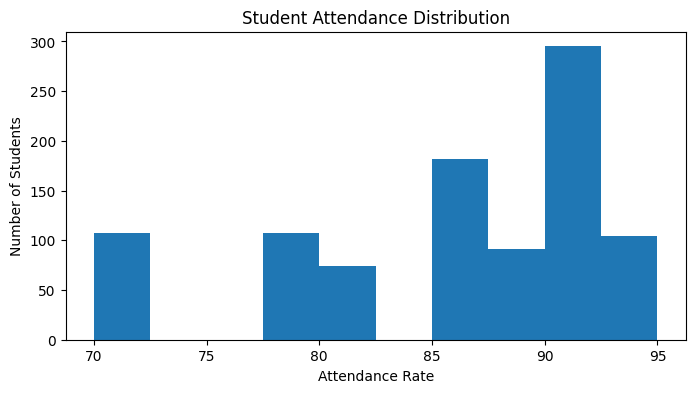

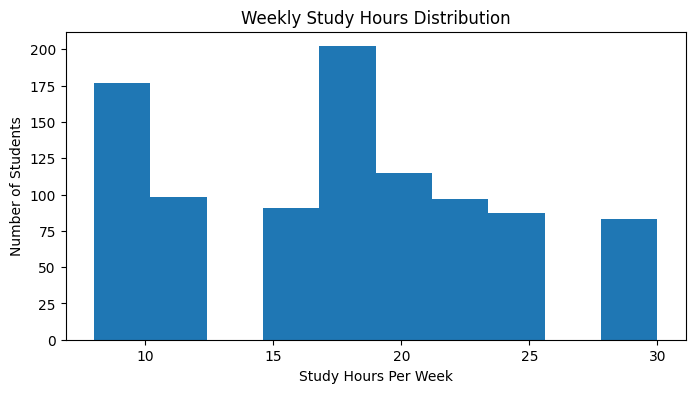


Dashboard analysis completed successfully!


In [11]:
import pandas as pd
import matplotlib.pyplot as plt
import streamlit as st

# Student Performance Dashboard
print("=" * 45)
print("     STUDENT PERFORMANCE DASHBOARD")
print("=" * 45)

print("\n1. DATASET OVERVIEW")
print("Total Students:", len(df))
print("Total Columns:", len(df.columns))

print("\n2. DATASET PREVIEW")
display(df.head(10))

print("\n3. STUDENT PERFORMANCE STATISTICS")
display(df.describe(include="all"))

print("\n4. MISSING VALUES")
display(df.isnull().sum())

# Attendance graph
if "AttendanceRate" in df.columns:
    plt.figure(figsize=(8, 4))
    plt.hist(df["AttendanceRate"].dropna(), bins=10)
    plt.title("Student Attendance Distribution")
    plt.xlabel("Attendance Rate")
    plt.ylabel("Number of Students")
    plt.show()

# Study hours graph
if "StudyHoursPerWeek" in df.columns:
    plt.figure(figsize=(8, 4))
    plt.hist(df["StudyHoursPerWeek"].dropna(), bins=10)
    plt.title("Weekly Study Hours Distribution")
    plt.xlabel("Study Hours Per Week")
    plt.ylabel("Number of Students")
    plt.show()

print("\nDashboard analysis completed successfully!")

In [12]:
import pickle
import pandas as pd

# Save model and dataset
with open("student_performance_model.pkl", "wb") as f:
    pickle.dump(model, f)

df.to_csv("student_performance_dataset.csv", index=False)

print("Project files saved successfully!")
print("Dataset:", df.shape)
print("Prediction target:", target)

Project files saved successfully!
Dataset: (1000, 12)
Prediction target: Attendance (%)
